# Predição de Reinternação Hospitalar de Pacientes Diabéticos em menos de 30 dias

**Disciplina:** Ciência de Dados e Big Data

| Item | Informação |
|---|---|
| **Integrantes** | Bernardo Dauber — *(nome do(a) integrante 2)* |
| **Dataset** | [Diabetes 130-US Hospitals for Years 1999-2008 (UCI)](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) |
| **Apresentação (slides)** | *(colar link — garantir acesso ao professor)* |
| **Vídeo (máx. 10 min)** | *(colar link — garantir acesso ao professor)* |

## 1. Contexto e problema

**Contexto.** A reinternação precoce de pacientes diabéticos é um indicador de qualidade do cuidado e gera custos elevados para sistemas de saúde. Identificar pacientes com maior risco de voltar ao hospital em menos de 30 dias permite priorizar acompanhamento pós-alta.

**Pergunta.** *É possível prever, a partir de dados da internação (perfil do paciente, procedimentos, medicamentos, diagnósticos), se um paciente diabético será reinternado em menos de 30 dias?*

**Tipo de problema.** Classificação supervisionada binária (`1` = reinternado em < 30 dias, `0` = caso contrário).

**Dataset.** ~100 mil internações em 130 hospitais dos EUA (1999–2008), ~50 variáveis (numéricas e categóricas), com valores faltantes e inconsistentes.

> TODO (dupla): reescrever esta seção com as palavras de vocês e acrescentar a motivação pessoal/social da escolha.

## 2. Importação das bibliotecas

In [1]:
import io
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 3. Aquisição e importação dos dados *(etapas 1 e 2)*

- **Fonte:** UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
- O arquivo principal é `diabetic_data.csv`; `IDs_mapping.csv` traz o significado dos códigos de admissão/alta.

A célula abaixo baixa e extrai o `.zip` automaticamente. Se o download falhar, baixe manualmente pelo link acima e envie `diabetic_data.csv` para o Colab.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
DATA_DIR = "data"
CSV_PATH = os.path.join(DATA_DIR, "diabetic_data.csv")

if not os.path.exists(CSV_PATH):
    os.makedirs(DATA_DIR, exist_ok=True)
    try:
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp:
            with zipfile.ZipFile(io.BytesIO(resp.read())) as z:
                z.extractall(DATA_DIR)
        print("Download e extração concluídos.")
    except Exception as e:
        print("Falha no download automático:", e)
        print("Baixe manualmente e coloque diabetic_data.csv em ./data/")

df_raw = pd.read_csv(CSV_PATH)
df = df_raw.copy()   # trabalhamos numa cópia; df_raw fica intacto para comparações
print("Importado com sucesso:", df.shape)

Download e extração concluídos.
Importado com sucesso: (101766, 50)


## 4. Análise exploratória inicial *(etapa 3)*

In [3]:
print("Dimensões (linhas, colunas):", df.shape)
df.head()

Dimensões (linhas, colunas): (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


In [6]:
# Estatísticas das colunas categóricas
df.describe(include="object").T

,count,unique,top,freq
race,101766,6,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,101766,10,?,98569
payer_code,101766,18,?,40256
medical_specialty,101766,73,?,49949
diag_1,101766,717,428,6862
diag_2,101766,749,276,6752
diag_3,101766,790,250,11555
max_glu_serum,5346,3,Norm,2597


In [7]:
# Valores faltantes: neste dataset eles aparecem como '?' (não como NaN)
missing_q = (df == "?").sum()
missing_q = missing_q[missing_q > 0].sort_values(ascending=False).to_frame("qtd_?")
missing_q["%"] = (missing_q["qtd_?"] / len(df) * 100).round(2)
print("Duplicatas de linhas inteiras:", df.duplicated().sum())
print("Pacientes únicos:", df["patient_nbr"].nunique(), "de", len(df), "internações")
missing_q

Duplicatas de linhas inteiras: 0
Pacientes únicos: 71518 de 101766 internações


,qtd_?,%
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


#### Observações — dados brutos

> - O dataset tem **101.766 linhas × 50 colunas**, com tipos numéricos e categóricos.
> - Os faltantes aparecem como `?`; `weight` tem **96.86%**, `medical_specialty` **49.08%** e `payer_code` **39.56%**.
> - Há **71.518 pacientes únicos** em 101.766 internações: o mesmo paciente aparece várias vezes.

## 5. Entendimento dos dados e das variáveis *(etapa 4)*

Dicionário resumido (fonte: UCI / artigo original *Strack et al., 2014*):

| Grupo | Variáveis | Descrição |
|---|---|---|
| Identificadores | `encounter_id`, `patient_nbr` | ID da internação e do paciente (**não são preditores**) |
| Demográficas | `race`, `gender`, `age`, `weight` | Perfil do paciente (`age` em faixas de 10 anos) |
| Admissão/alta | `admission_type_id`, `admission_source_id`, `discharge_disposition_id` | Códigos categóricos (ver `IDs_mapping.csv`) |
| Cuidado | `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications` | Contagens/duração da internação |
| Histórico | `number_outpatient`, `number_emergency`, `number_inpatient` | Visitas no ano anterior |
| Diagnóstico | `diag_1`, `diag_2`, `diag_3`, `number_diagnoses` | Códigos CID-9 e quantidade de diagnósticos |
| Exames | `max_glu_serum`, `A1Cresult` | Glicose sérica e HbA1c |
| Medicamentos | 23 colunas (`metformin`, `insulin`, ...) | `No`, `Steady`, `Up`, `Down` |
| Gerais | `change`, `diabetesMed`, `payer_code`, `medical_specialty` | Mudança de medicação, uso de antidiabéticos, convênio, especialidade |
| **Alvo** | `readmitted` | `NO`, `>30`, `<30` dias |

> TODO (dupla): descrever em texto corrido o que cada grupo significa clinicamente e quais variáveis vocês esperam que mais influenciem o alvo (hipóteses — voltaremos a elas na conclusão).

### 5.1 Definição da variável-alvo

Transformamos `readmitted` em **binária**: `1` se `<30` (reinternação precoce), `0` caso contrário (`>30` ou `NO`). Isso reflete a métrica usada por hospitais (readmissão em 30 dias).

In [8]:
df["target"] = (df["readmitted"] == "<30").astype(int)
print(df["readmitted"].value_counts())
print("\nProporção do alvo binário:")
print(df["target"].value_counts(normalize=True).round(3))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Proporção do alvo binário:
target
0    0.888
1    0.112
Name: proportion, dtype: float64


## 6. Visualização dos dados *(etapa 5)*

Gráficos exploratórios sobre o alvo, distribuições numéricas, categóricas e relações entre variáveis.

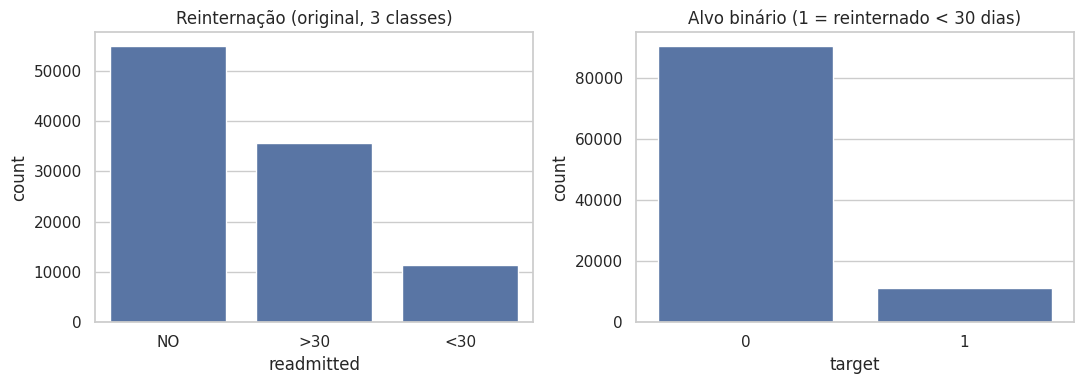

In [9]:
# 6.1 Distribuição do alvo (desbalanceamento)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], ax=ax[0])
ax[0].set_title("Reinternação (original, 3 classes)")
sns.countplot(data=df, x="target", ax=ax[1])
ax[1].set_title("Alvo binário (1 = reinternado < 30 dias)")
plt.tight_layout(); plt.show()

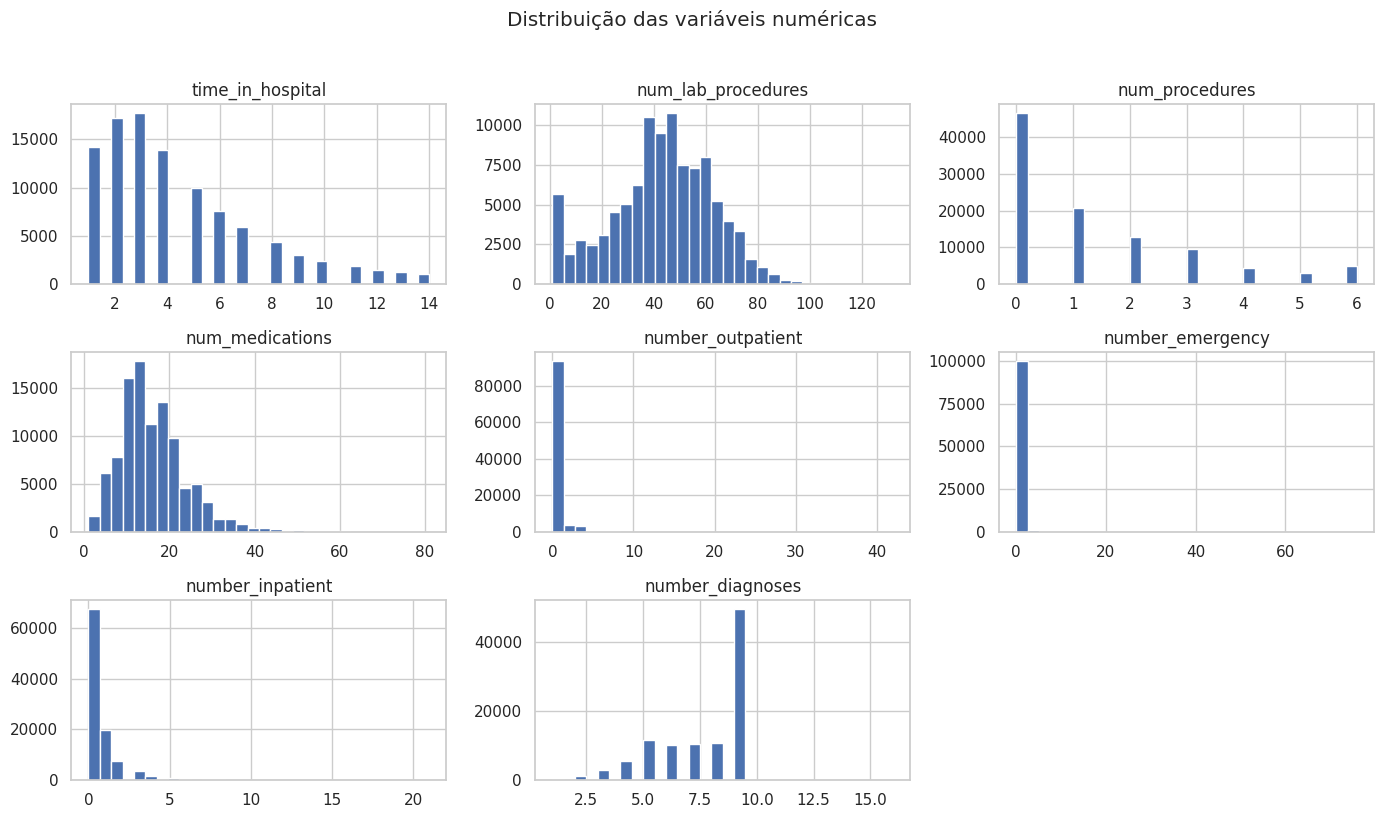

In [10]:
# 6.2 Histogramas das variáveis numéricas
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.suptitle("Distribuição das variáveis numéricas", y=1.02)
plt.tight_layout(); plt.show()

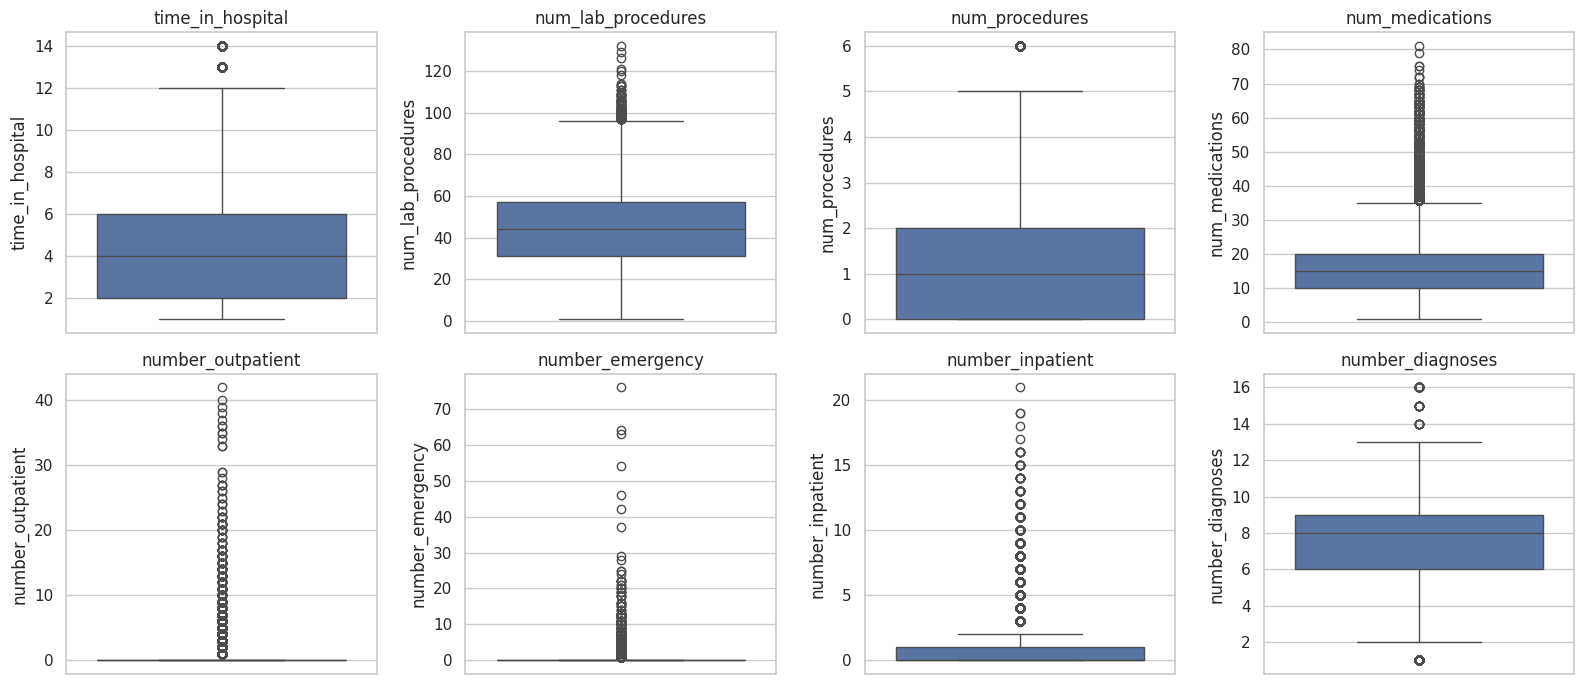

In [11]:
# 6.3 Boxplots (outliers) das variáveis numéricas
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

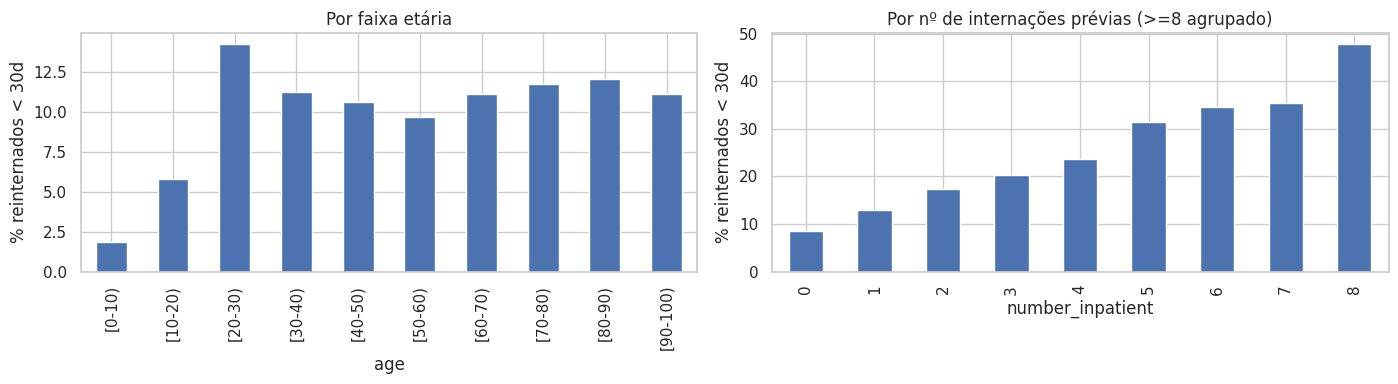

In [12]:
# 6.4 Taxa de reinternação < 30 dias por faixa etária e por nº de internações prévias
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby("age")["target"].mean() * 100).plot(kind="bar", ax=ax[0])
ax[0].set_ylabel("% reinternados < 30d"); ax[0].set_title("Por faixa etária")
(df.groupby(df["number_inpatient"].clip(upper=8))["target"].mean() * 100).plot(kind="bar", ax=ax[1])
ax[1].set_ylabel("% reinternados < 30d"); ax[1].set_title("Por nº de internações prévias (>=8 agrupado)")
plt.tight_layout(); plt.show()

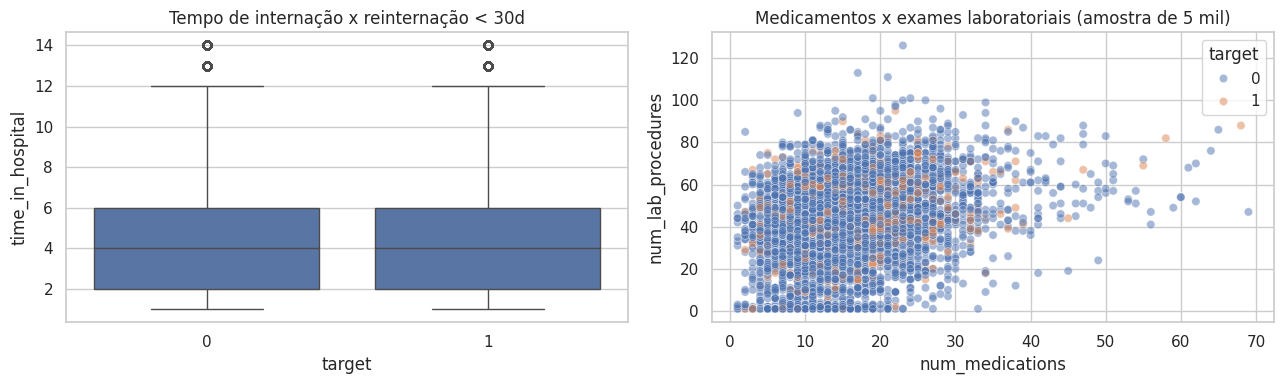

In [13]:
# 6.5 Boxplot de variável numérica x alvo + dispersão
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="target", y="time_in_hospital", ax=ax[0])
ax[0].set_title("Tempo de internação x reinternação < 30d")
sns.scatterplot(data=df.sample(5000, random_state=RANDOM_STATE),
                x="num_medications", y="num_lab_procedures", hue="target", alpha=0.5, ax=ax[1])
ax[1].set_title("Medicamentos x exames laboratoriais (amostra de 5 mil)")
plt.tight_layout(); plt.show()

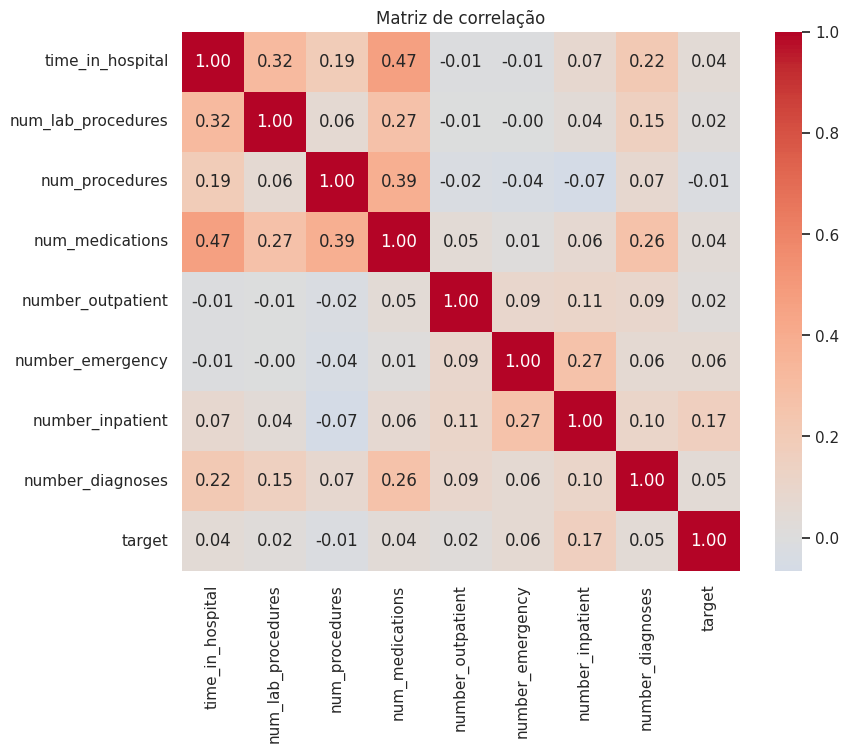

In [14]:
# 6.6 Correlação entre variáveis numéricas
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação"); plt.show()

#### Observações — gráficos

> - Só **11.2%** das internações terminam em reinternação em menos de 30 dias: o alvo é altamente desbalanceado.
> - As variáveis `number_*` (como `number_inpatient`, `number_outpatient` e `number_emergency`) são muito assimétricas, com forte concentração em zero e longas caudas à direita com a presença de outliers evidentes.
> - Há uma tendência clara de aumento na taxa de reinternação conforme aumenta o número de internações prévias (passando de 8,5% sem internações prévias para 47,8% nos pacientes com 8 ou mais internações).
> - As correlações entre as variáveis numéricas são majoritariamente fracas a moderadas, sendo a maior correlação observada de **0.47** (entre `num_medications` e `time_in_hospital`).

## 7. Tratamento de dados inválidos ou inconsistentes *(etapa 6)*

Problemas identificados e decisões:

1. **`?`** representa ausência → converter para `NaN` (tratado na seção 8).
2. **`gender = 'Unknown/Invalid'`** (poucos registros) → remover.
3. **Óbitos/hospice** (`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21}): esses pacientes **não podem ser reinternados** → remover para não distorcer o modelo.
4. **Múltiplas internações do mesmo paciente** violam a independência das amostras e podem causar *vazamento* entre treino e teste → manter apenas a **primeira internação por paciente**.
5. **Colunas constantes** (ex.: `examide`, `citoglipton` têm apenas 'No') → serão descartadas na seleção de atributos.

In [15]:
n0 = len(df)

# 1) '?' -> NaN
df = df.replace("?", np.nan)

# 2) gênero inválido
df = df[df["gender"] != "Unknown/Invalid"]

# 3) óbito / hospice
obito_hospice = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(obito_hospice)]

# 4) uma internação por paciente (a primeira, por encounter_id)
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")

print(f"Linhas antes: {n0:,} | depois: {len(df):,} (removidas {n0 - len(df):,})")
print("Taxa do alvo após limpeza:", df["target"].mean().round(4))

Linhas antes: 101,766 | depois: 69,987 (removidas 31,779)
Taxa do alvo após limpeza: 0.0898


#### Observações — dados inválidos

> - Passamos de **101.766 para 69.987 linhas** depois de remover gênero inválido, óbito/hospice e manter apenas a primeira internação por paciente.
> - A taxa do alvo foi de **11.2%** para **8.98%** depois da limpeza.

## 8. Tratamento de dados faltantes *(etapa 7)*

Estratégia por coluna, baseada no percentual de faltantes:

| Coluna | Estratégia | Justificativa |
|---|---|---|
| `weight` | **Remover coluna** | ~97% faltante: imputar seria inventar dado |
| `payer_code`, `medical_specialty` | Categoria `"Desconhecido"` | ~40–50% faltante; a ausência pode ser informativa |
| `race`, `diag_1/2/3` | Categoria `"Desconhecido"` | Poucos faltantes; preserva as linhas |
| `max_glu_serum`, `A1Cresult` | Já são `None`/`Norm`/`>X` (exame não realizado é categoria válida) | Não são `NaN` |

In [16]:
miss = (df.isna().mean() * 100).round(2)
miss[miss > 0].sort_values(ascending=False)

,0
weight,96.02
max_glu_serum,95.21
A1Cresult,81.65
medical_specialty,48.08
payer_code,43.46
race,2.74
diag_3,1.75
diag_2,0.42
diag_1,0.01


In [17]:
df = df.drop(columns=["weight"])

cols_desconhecido = ["payer_code", "medical_specialty", "race", "diag_1", "diag_2", "diag_3"]
df[cols_desconhecido] = df[cols_desconhecido].fillna("Desconhecido")

print("Faltantes restantes:", int(df.isna().sum().sum()))

Faltantes restantes: 123779


#### Observações — faltantes

> - `weight` foi removida (faltante em cerca de 96.02% na base filtrada); as demais colunas viraram a categoria “Desconhecido”.
> - Faltantes restantes: **123.779**, todos em `max_glu_serum` e `A1Cresult`, onde o nulo significa exame não realizado e é mantido como categoria (o `OneHotEncoder` trata o nulo como categoria própria). Nas demais colunas, os faltantes são 0: a categoria “Desconhecido” cobre `payer_code`, `medical_specialty`, `race` e `diag_1/2/3`.

## 9. Engenharia e seleção de atributos *(etapa 8)*

- **Remover identificadores:** `encounter_id`, `patient_nbr` (não generalizam).
- **Remover `readmitted`:** é a origem do alvo (*vazamento direto*).
- **Remover colunas constantes/quase constantes** (ex.: `examide`, `citoglipton`).
- **Agrupar diagnósticos CID-9** (`diag_1/2/3` têm centenas de códigos) em categorias clínicas.
- **`age`** é ordinal → converter faixa para o ponto médio (ex.: `[70-80)` → 75).
- **`medical_specialty`** e **`payer_code`** têm alta cardinalidade → manter apenas as categorias mais frequentes e agrupar o resto em `Outros`.

In [18]:
# 9.1 Descartar identificadores, vazamento e colunas constantes
df = df.drop(columns=["encounter_id", "patient_nbr", "readmitted"])

constantes = [c for c in df.columns if df[c].nunique() <= 1]
print("Colunas constantes removidas:", constantes)
df = df.drop(columns=constantes)

# Colunas de medicamentos com variância quase nula (>99,5% 'No')
meds = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride","acetohexamide",
        "glipizide","glyburide","tolbutamide","pioglitazone","rosiglitazone","acarbose","miglitol",
        "troglitazone","tolazamide","insulin","glyburide-metformin","glipizide-metformin",
        "glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]
meds = [m for m in meds if m in df.columns]
quase_const = [m for m in meds if (df[m] == "No").mean() > 0.995]
print("Medicamentos quase constantes removidos:", quase_const)
df = df.drop(columns=quase_const)

Colunas constantes removidas: ['examide', 'citoglipton', 'glimepiride-pioglitazone']
Medicamentos quase constantes removidos: ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glipizide-metformin', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [19]:
# 9.2 Agrupar códigos CID-9 em categorias clínicas
def agrupar_diag(code):
    if code == "Desconhecido":
        return "Desconhecido"
    if str(code).startswith(("V", "E")):
        return "Outros"
    try:
        v = float(code)
    except ValueError:
        return "Outros"
    if 390 <= v <= 459 or v == 785: return "Circulatório"
    if 460 <= v <= 519 or v == 786: return "Respiratório"
    if 520 <= v <= 579 or v == 787: return "Digestivo"
    if int(v) == 250:               return "Diabetes"
    if 800 <= v <= 999:             return "Lesões"
    if 710 <= v <= 739:             return "Musculoesquelético"
    if 580 <= v <= 629 or v == 788: return "Geniturinário"
    if 140 <= v <= 239:             return "Neoplasias"
    return "Outros"

for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = df[c].apply(agrupar_diag)

# 9.3 Idade: faixa -> ponto médio (variável ordinal tratada como numérica)
df["age"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)

# 9.4 Alta cardinalidade: manter as 10 categorias mais frequentes
for c in ["medical_specialty", "payer_code"]:
    top = df[c].value_counts().nlargest(10).index
    df[c] = df[c].where(df[c].isin(top), "Outros")

# 9.5 Códigos numéricos que na verdade são categorias
for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[c] = df[c].astype(str)

print("Shape após seleção/engenharia:", df.shape)
df.head()

Shape após seleção/engenharia: (69987, 34)


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin,glyburide-metformin,change,diabetesMed,target
8,Caucasian,Female,85.0,2,1,4,13,Desconhecido,Desconhecido,68,2,28,0,0,0,Circulatório,Circulatório,Outros,8,NaN,NaN,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,0
9,Caucasian,Female,95.0,3,3,4,12,Desconhecido,InternalMedicine,33,3,18,0,0,0,Circulatório,Neoplasias,Respiratório,8,NaN,NaN,No,No,No,No,No,No,No,Steady,Steady,No,Ch,Yes,0
4,Caucasian,Male,45.0,1,1,7,1,Desconhecido,Desconhecido,51,0,8,0,0,0,Neoplasias,Neoplasias,Diabetes,5,NaN,NaN,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,0
10,AfricanAmerican,Female,45.0,1,1,7,9,Desconhecido,Desconhecido,47,2,17,0,0,0,Diabetes,Circulatório,Lesões,9,NaN,NaN,No,No,No,No,No,No,No,No,Steady,No,No,Yes,0
5,Caucasian,Male,55.0,2,1,2,3,Desconhecido,Desconhecido,31,6,16,0,0,0,Circulatório,Circulatório,Diabetes,9,NaN,NaN,No,No,No,No,No,No,No,No,Steady,No,No,Yes,0


## 10. Classificação das variáveis *(etapa 9)*

| Tipo | Variáveis |
|---|---|
| **Numéricas discretas** (contagens) | `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_outpatient`, `number_emergency`, `number_inpatient`, `number_diagnoses` |
| **Numérica ordinal tratada como contínua** | `age` (ponto médio da faixa) |
| **Categóricas nominais** | `race`, `gender`, `admission_type_id`, `discharge_disposition_id`, `admission_source_id`, `payer_code`, `medical_specialty`, `diag_1/2/3`, `change`, `diabetesMed`, medicamentos restantes |
| **Categóricas ordinais** | `max_glu_serum`, `A1Cresult` (`None` < `Norm` < `>7`/`>200` < `>8`/`>300`) — por simplicidade tratadas como nominais via One-Hot |
| **Alvo (binária)** | `target` |

> Nenhuma variável é contínua no sentido estrito (todas as numéricas são contagens/durações inteiras, exceto `age` que foi derivada).

In [20]:
TARGET = "target"
num_features = ["age"] + [c for c in df.columns if c.startswith(("time_", "num_", "number_"))]
cat_features = [c for c in df.columns if c not in num_features + [TARGET]]

print("Numéricas  (%d):" % len(num_features), num_features)
print("Categóricas (%d):" % len(cat_features), cat_features)

Numéricas  (9): ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categóricas (24): ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed']


#### Observações — atributos

> - Ficamos com **9 numéricas** e **24 categóricas**, depois de remover IDs, `readmitted` e colunas constantes.
> - Colunas de medicamentos removidas por serem quase constantes: `chlorpropamide`, `acetohexamide`, `tolbutamide`, `acarbose`, `miglitol`, `troglitazone`, `tolazamide`, `glipizide-metformin`, `metformin-rosiglitazone` e `metformin-pioglitazone`.

## 11. Separação entre preditores (X) e alvo (y) *(etapa 10)*

In [21]:
X = df[num_features + cat_features]
y = df[TARGET]
print("X:", X.shape, "| y:", y.shape)

X: (69987, 33) | y: (69987,)


## 12. Divisão em treino e teste *(etapa 13)*

Divisão **antes** de qualquer escalonamento/codificação ajustada, para evitar *data leakage*. Usamos `stratify=y` para manter a proporção do alvo (desbalanceado) em ambos os conjuntos.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Proporção do alvo — treino: %.3f | teste: %.3f" % (y_train.mean(), y_test.mean()))

Treino: (55989, 33) | Teste: (13998, 33)
Proporção do alvo — treino: 0.090 | teste: 0.090


## 13. Transformações e padronização *(etapas 11 e 12)*

Usamos um `ColumnTransformer` dentro de um `Pipeline`:

- **Numéricas:** `StandardScaler` (média 0, desvio 1) — necessário para a Regressão Logística.
- **Categóricas:** `OneHotEncoder(handle_unknown="ignore")` — transforma categorias em colunas binárias.

O pré-processador é **ajustado apenas no treino** (`fit`) e aplicado ao teste (`transform`) automaticamente pelo pipeline.

In [23]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

# Visualizar o efeito da transformação (apenas para inspeção)
Xt = preprocess.fit_transform(X_train)
print("Shape após transformação:", Xt.shape)

Shape após transformação: (55989, 167)


#### Observações — transformações

> - Depois do `OneHotEncoder` o conjunto de treino passou a ter **167 colunas** devido à expansão das variáveis categóricas.
> - O pré-processador é ajustado só no treino, o que evita vazamento para o teste.

## 14. Treinamento dos modelos *(etapa 14)*

Dois modelos para permitir comparação crítica:

1. **Regressão Logística** — *baseline* interpretável.
2. **Random Forest** — modelo não linear, captura interações e é robusto a outliers.

Como o alvo é desbalanceado (~9–11% de positivos), usamos `class_weight="balanced"` para penalizar mais os erros na classe minoritária.

In [24]:
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                            class_weight="balanced", n_jobs=-1,
                                            random_state=RANDOM_STATE),
}

pipes = {}
for nome, clf in modelos.items():
    pipes[nome] = Pipeline([("prep", preprocess), ("clf", clf)])
    pipes[nome].fit(X_train, y_train)
    print(f"{nome}: treinado.")

Regressão Logística: treinado.
Random Forest: treinado.


## 15. Avaliação dos modelos *(etapa 15)*

**Atenção à métrica:** com ~10% de positivos, um modelo que sempre prevê "não reinterna" teria ~90% de acurácia e seria inútil. Por isso olhamos **recall** (quantos reinternados detectamos), **precisão**, **F1** e **ROC-AUC**.

In [25]:
# Baseline trivial para referência (sempre prevê a classe majoritária)
print("Acurácia do 'modelo burro' (sempre 0): %.3f" % (1 - y_test.mean()))

resultados = []
for nome, pipe in pipes.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })
pd.DataFrame(resultados).set_index("Modelo").round(3)

Acurácia do 'modelo burro' (sempre 0): 0.910


,Acurácia,Precisão,Recall,F1,ROC-AUC
Modelo,,,,,
Regressão Logística,0.663,0.138,0.522,0.218,0.649
Random Forest,0.708,0.154,0.501,0.236,0.659


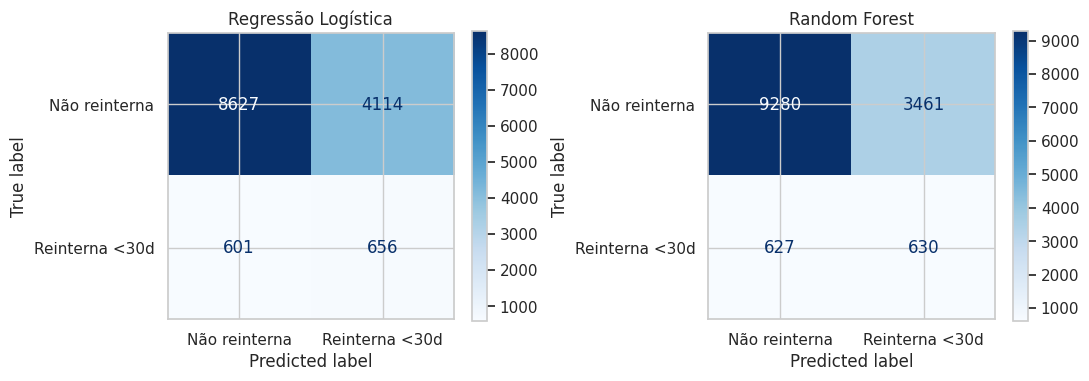

In [26]:
# Matrizes de confusão
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, pipe) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, cmap="Blues",
                                          display_labels=["Não reinterna", "Reinterna <30d"])
    ax.set_title(nome)
plt.tight_layout(); plt.show()

Regressão Logística
                precision    recall  f1-score   support

 Não reinterna       0.93      0.68      0.79     12741
Reinterna <30d       0.14      0.52      0.22      1257

      accuracy                           0.66     13998
     macro avg       0.54      0.60      0.50     13998
  weighted avg       0.86      0.66      0.73     13998

Random Forest
                precision    recall  f1-score   support

 Não reinterna       0.94      0.73      0.82     12741
Reinterna <30d       0.15      0.50      0.24      1257

      accuracy                           0.71     13998
     macro avg       0.55      0.61      0.53     13998
  weighted avg       0.87      0.71      0.77     13998



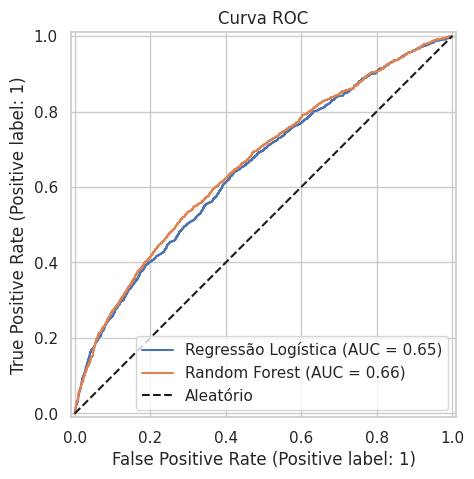

In [27]:
# Relatório de classificação e curva ROC
for nome, pipe in pipes.items():
    print("=" * 60); print(nome); print("=" * 60)
    print(classification_report(y_test, pipe.predict(X_test),
                                target_names=["Não reinterna", "Reinterna <30d"]))

fig, ax = plt.subplots(figsize=(6, 5))
for nome, pipe in pipes.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Aleatório")
ax.set_title("Curva ROC"); ax.legend(); plt.show()

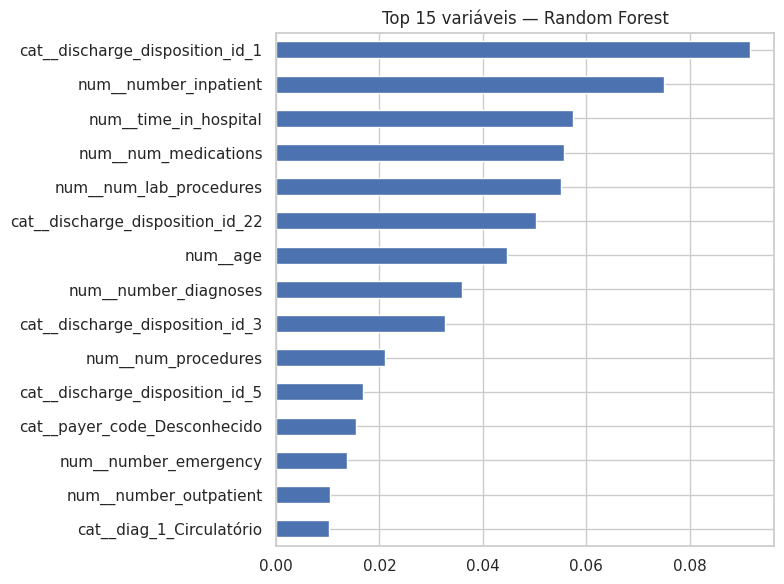

In [28]:
# Importância das variáveis (Random Forest) — interpretabilidade
rf = pipes["Random Forest"]
nomes = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=nomes).nlargest(15)
imp.sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 variáveis — Random Forest")
plt.tight_layout(); plt.show()

#### Observações — resultados

> - **Regressão Logística:** acurácia [0.663], precisão [0.138], recall [0.522], F1 [0.218], ROC-AUC [0.649].
> - **Random Forest:** acurácia [0.708], precisão [0.154], recall [0.501], F1 [0.236], ROC-AUC [0.659].
> - O modelo que sempre prevê “não” teria acurácia de **91.0%**: por isso olhamos métricas como recall e F1 para validar o real poder preditivo do modelo na classe minoritária.
> - A matriz de confusão do melhor modelo (Random Forest) tem **627 falsos negativos** (deixou de identificar pacientes que reinternaram) e **3.461 falsos positivos** (indicou risco de reinternação para quem não retornou).
> - Variáveis mais importantes: `discharge_disposition_id_1` (alta para casa), `number_inpatient` (histórico de internação prévia) e `time_in_hospital` (tempo de internação). Isso **confirma** nossa hipótese inicial de que o histórico recente de uso do sistema de saúde e a severidade do caso atual seriam os preditores mais relevantes.

## 16. Conclusões e análise crítica

> TODO (dupla): preencher com base nos resultados reais após executar o notebook.

**Pontos a discutir:**
- **Qual modelo foi melhor e por quê?** Comparar recall/F1/AUC, não só acurácia.
- **O desempenho é suficiente?** Em geral, esse problema tem AUC modesta (~0,60–0,68): os dados de internação sozinhos explicam pouco da reinternação.
- **Trade-off precisão x recall:** em saúde, o custo de um falso negativo (paciente de risco não detectado) costuma ser maior que o de um falso positivo. Discutir o ajuste do limiar de decisão.
- **Variáveis mais importantes:** confirmam ou contradizem as hipóteses da seção 5? (esperado: `number_inpatient`, `number_diagnoses`, `discharge_disposition_id`, `num_medications`).
- **Limitações:** dados de 1999–2008; só hospitais dos EUA; sem dados socioeconômicos ou de adesão ao tratamento; desbalanceamento; uma internação por paciente reduz o volume.
- **Vieses/ética:** uso de `race` e `gender` em modelos clínicos exige cautela; risco de discriminação.
- **Melhorias futuras:** `GridSearchCV`/`RandomizedSearchCV`, validação cruzada, SMOTE, Gradient Boosting (XGBoost/LightGBM), ajuste de limiar, mais engenharia de atributos.

**Referências**
- Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International.
- UCI Machine Learning Repository — Diabetes 130-US hospitals for years 1999-2008.